# Estimating fish locations with Pangeo-Fish

**Where might a fish have travelled between release and recapture?** In this Notebook, we combine temperatures recorded by a tag with ocean-model temperatures and acoustic detections to estimate possible locations over time.

We use tag `A19124` from the study by M. Gonse et al., "Combining acoustic telemetry with archival tagging to investigate the spatial dynamic of the understudied pollack, *Pollachius pollachius*", *Journal of Fish Biology* 106(5): 1400–1421 (2024), [doi:10.1111/jfb.15750](https://doi.org/10.1111/jfb.15750). Its Data Storage Tag (DST) records temperature and depth. Release and recapture/death information provide additional constraints.

Select the **Python (pangeo-fish)** kernel



**Workflow.**

1. **Prepare the analysis:** load the tools and choose the study settings.
2. **Compare temperatures:** compare tag observations with ocean-model temperatures at candidate locations.
3. **Use an equal-area grid:** represent candidate locations as HEALPix cells.
4. **Identify locations consistent with temperature:** give greater weight to closer temperature matches.
5. **Add acoustic detections:** constrain locations using receiver detections.
6. **Combine the evidence:** bring these observations together at each time step.
7. **Estimate movement:** fit how widely the fish can move between time steps.
8. **Estimate locations and tracks:** combine the observations with the movement model.
9. **Explore the results:** inspect maps, compare tracks, and make a video.


We use a Hidden Markov Model (HMM) to connect the observations over time. The fish's location is unknown; the model estimates its possible locations using both the observations and assumptions about movement.

## 1. Prepare the analysis

Run the cells from top to bottom. Click a code cell and press **Shift+Enter** to run it and move to the next cell. Wait for each calculation to finish before continuing. If a cell shows an error, ask an instructor before running the following steps. If you report a problem later, run the cell in the appendix **Information for bug reports** at the end of this notebook and copy its output into your report.

Run the setup cells below without changing them.

In [52]:
# Use CPU execution.
import torch
import os

os.environ["CUDA_VISIBLE_DEVICES"] = ""

### Load the analysis tools

In [53]:
from pint_xarray import unit_registry as ureg
import hvplot.xarray
import xarray as xr
import sys


# sys.path.append("../")
import pangeo_fish
from pangeo_fish.xarray_update import Accessor
from pangeo_fish.helpers import multiplot_healpix, multi_map_with_synced_sliders

### Study settings

All settings are collected here and grouped by the section that uses them. Keep the supplied values for your first run. For your own study, the tag, study area, temperature tolerance, and receiver detection range are particularly important choices.

In [54]:
# SECTION 1 — Initialization and configuration
# Tag identifier; the last assignment selects A19124.
tag_name = "A18828"
# tag_name = "A19124"


# Tag data location: a public URL, local path, or s3:// bucket path.
tag_root = "https://data-taos.ifremer.fr/demo/tag/tag/"

tag_storage_options = None
# Backup: the same tag data mirrored on the Pangeo@EOSC MinIO (public, read-only).
# If data-taos.ifremer.fr is unreachable, use these two lines instead.
# tag_root = "s3://todaka-pangeo-fish-demo/tag"
# tag_storage_options = {
#     "anon": True,
#     "client_kwargs": {"endpoint_url": "https://pangeo-eosc-minioapi.vm.fedcloud.eu"},
# }

# Folder for saving results.
scratch_root = "./test"

# Connection settings for reading/writing results under scratch_root.
# None uses default settings.
# For an s3:// scratch_root, provide credentials/profile or endpoint options.
storage_options = None

# Number of time steps processed together. Default value.
# 1 = one time step per chunk; -1 = all time steps in one chunk.
chunk_time = 1

# SECTION 2 — Compare reference ocean data with DST observations
# Select the Copernicus Marine ocean model; keep only one assignment active.
# Both options work; better starting with IBI.

# IBI Reanalysis — Regional model, ~3 km, daily (default)
# https://data.marine.copernicus.eu/product/IBI_MULTIYEAR_PHY_005_002
copernicus_model_name = "cmems_mod_ibi_phy-temp_my_0.027deg_P1D-m"

# GLORYS12 Reanalysis — Global model, ~9 km, daily
# https://data.marine.copernicus.eu/product/GLOBAL_MULTIYEAR_PHY_001_030
# copernicus_model_name = "cmems_mod_glo_phy_my_0.083deg_P1D-m"

# Read the selected model from Copernicus Marine.
ref_url = None  # Default value

# Geographic bounds for model loading; also used in Sections 3 and 9.
bbox = {"latitude": [46, 51.5], "longitude": [-7, 0]}

# Reject cells where the model seabed is too shallow for the depths the fish
# was recorded at. A cell is rejected if its seabed is shallower than this
# fraction of the maximum tag depth in the same model time bin.
# Range: 0 or more; useful values are between 0 and 1.
#   0    = filter off: every cell is kept (default value)
#   0.8  = the seabed must be at least 80% of the deepest tag depth
#          (allows some error in the model bathymetry)
#   1    = the seabed must be at least as deep as the deepest tag depth
# Larger values reject more cells (stricter); values above 1 also reject
# cells whose seabed is only slightly deeper than the fish.
relative_depth_threshold = 0

# SECTION 3 — HEALPix regridding
# Use HEALPix cells for the analysis. Keep this setting for Sections 3–8.
dims = ["cells"]

# HEALPix resolution (approximate equivalent pixel size)
# Each refinement level divides the cell area by 4.
# Total number of cells = 12 * 4**refinement_level
# Equivalent size = sqrt(cell area) on a spherical Earth of radius 6371 km,
# not an exact geometric edge length.
#
# refinement_level = 10  # ~6.4 km
refinement_level = 11  # ~3.2 km (similar to the 3 km IBI model)
# refinement_level = 12  # ~1.6 km
#
# Higher refinement levels provide finer spatial resolution
# but increase the number of cells and computational cost.

# Earth shape used for the HEALPix regridding in Section 3. It is stored with
# the grid, and the maps and the movement search read it from there. Keep "sphere" here.
ellipsoid = "sphere"
# ellipsoid = "WGS84"  # Recommended when Earth's flattening matters for the required accuracy.

# SECTION 4 — Temperature-based emission probability
# Temperature tolerance (°C): larger values allow a wider range of
# differences between tag and model temperatures (Gaussian standard deviation).
differences_std = 0.75
# Spread around the known release and recapture/death locations: the standard
# deviation of a Gaussian, as an angle in radians on the Earth. Multiply by
# the Earth radius to get a distance: 1e-4 rad x 6371 km ≈ 0.64 km.
# This is smaller than one HEALPix cell (~3.2 km at level 11), so the location
# is effectively fixed to the release (or recapture) cell.
# Smaller values give tighter spatial constraints. Keep these default values.
initial_std = 1e-4
recapture_std = 1e-4

# SECTION 5 — Acoustic detection probability
# Maximum detection distance assumed around each receiver.
receiver_buffer = ureg.Quantity(2000, "m")

# SECTION 7 — Optimization of movement parameters
# The Earth radius used to convert movement distances into angles is derived
# from the ellipsoid stored with the HEALPix grid (about 6371 km for "sphere").
# Speed scale used to set the upper search limit for the movement parameter.
# This is not a strict speed limit on every possible movement.
maximum_speed = ureg.Quantity(60, "km / day")
# Multiplier for the upper limit of sigma values tried during fitting.
# 1 uses the limit set by maximum_speed and the model time interval;
# 2 doubles that limit. It does not directly multiply the fitted movement.
# Keep 1 by default. This is unrelated to video frame sampling.
adjustment_factor = 1
# Used with HealpixConv; not used by LargeHealpixConv or FoscatConv.
truncate = 4  # Default value
# Numerical precision of the parameter search. default value.
tolerance = 1e-6

# SECTION 8 — State probabilities and trajectories
# Trajectory summaries: mean position and most probable cell at each time step.
# Also used for plotting in Section 9.
track_modes = ["mean", "mode"]
# Supported here: "speed" (km/h) and "distance" to the previous point (km).
# Other quantities can be calculated afterward; see the optional note in Section 8.
additional_track_quantities = ["speed", "distance"]

# SECTION 9 — Visualization and video generation
# Number of data time steps between video frames
# 1 = include every time step
# 3 = include every third time step
# The current video tool omits the final time step; see Section 9.
time_step = 1

In [55]:
# Define target root directories for storing analysis results.
target_root = f"{scratch_root}/{tag_name}"

# Defines default chunk size for optimization.
default_chunk = {"time": chunk_time, "lat": -1, "lon": -1}
default_chunk_dims = {"time": chunk_time}
default_chunk_dims.update({d: -1 for d in dims})

### Prepare the calculations

Run this cell to start Dask, which shares calculations across the available computing resources. No settings need to be changed here.

In [56]:
# Set up a local cluster for distributed computing.
from distributed import LocalCluster

cluster = LocalCluster()
client = cluster.get_client()
client

/home/cchauveau/micromamba/envs/pangeo-fish-pr262/lib/python3.11/site-packages/distributed/node.py:188: UserWarning: Port 8787 is already in use.
Perhaps you already have a cluster running?
Hosting the HTTP server on port 42651 instead
  warnings.warn(


Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: http://127.0.0.1:42651/status,
Dashboard: http://127.0.0.1:42651/status,Workers: 4
Total threads: 16,Total memory: 24.75 GiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:34357,Workers: 0
Dashboard: http://127.0.0.1:42651/status,Total threads: 0
Started: Just now,Total memory: 0 B
Comm: tcp://127.0.0.1:36337,Total threads: 4
Dashboard: http://127.0.0.1:44669/status,Memory: 6.19 GiB
Nanny: tcp://127.0.0.1:43855,


2026-10-27 15:47:18,997 - distributed.shuffle._scheduler_plugin - WARNING - Shuffle c21ca26de5dd0f03906f7dad6e55119e initialized by task ('rechunk-merge-rechunk-transfer-e108f1965e1fa73bf04a49925df1bc05', 0, 0, 0, 0, 0, 0) executed on worker tcp://127.0.0.1:32975
2026-10-27 15:47:20,116 - distributed.shuffle._scheduler_plugin - WARNING - Shuffle c21ca26de5dd0f03906f7dad6e55119e deactivated due to stimulus 'task-finished-1793116040.1139736'
2026-10-27 15:47:51,040 - distributed.shuffle._scheduler_plugin - WARNING - Shuffle 398fde5a2e1ca9d1b1e0511ef034e428 initialized by task ('rechunk-merge-rechunk-transfer-3461829727e80c7768195fb82913c027', 0, 0, 0, 0, 0, 0, 3, 6) executed on worker tcp://127.0.0.1:32975
2026-10-27 15:49:28,890 - distributed.shuffle._scheduler_plugin - WARNING - Shuffle c21ca26de5dd0f03906f7dad6e55119e initialized by task ('rechunk-merge-rechunk-transfer-e108f1965e1fa73bf04a49925df1bc05', 0, 0, 0, 0, 0, 0) executed on worker tcp://127.0.0.1:32975
2026-10-27 15:49:30,53

### Load the tag observations

Load the temperature, depth, and event information for the selected fish.

In [57]:
from pangeo_fish.helpers import load_tag

tag, tag_log, time_slice = load_tag(
    tag_root=tag_root, tag_name=tag_name, storage_options=tag_storage_options
)
tag

<xarray.DataTree>
Group: /
│   Attributes:
│       pit_tag_id:       A18828
│       acoustic_tag_id:  OPI-378
│       scientific_name:  Pollachius pollachius
│       common_name:      Pollock
│       project:          FISHINTEL
│       tag_name:         A18828
├── Group: /dst
│       Dimensions:      (time: 366128)
│       Coordinates:
│         * time         (time) datetime64[ns] 3MB 2022-06-16T22:00:00 ... 2023-07-03...
│       Data variables:
│           temperature  (time) float64 3MB 18.08 18.08 18.08 ... 20.83 21.11 22.56
│           pressure     (time) float64 3MB 4.31 4.31 4.31 4.37 ... 6.62 6.5 6.37 6.37
├── Group: /tagging_events
│       Dimensions:     (event_name: 2)
│       Coordinates:
│         * event_name  (event_name) object 16B 'release' 'fish_death'
│       Data variables:
│           time        (event_name) datetime64[ns] 16B 2022-06-17T10:57:00 2023-06-2...
│           longitude   (event_name) float64 16B -4.907 -5.017
│           latitude    (event_name) float64 16B 48.44 48.45
├── Group: /stations
│       Dimensions:            (deployment_id: 41)
│       Coordinates:
│         * deployment_id      (deployment_id) int64 328B 28689 28690 ... 29666 59010
│       Data variables:
│           station_name       (deployment_id) object 328B 'ancrage_mahuda' ... 'stiff'
│           deploy_time        (deployment_id) datetime64[ns] 328B 2022-06-13T06:14:0...
│           deploy_longitude   (deployment_id) float64 328B -5.103 -5.112 ... -5.025
│           deploy_latitude    (deployment_id) float64 328B 48.45 48.45 ... 48.47 48.47
│           recover_time       (deployment_id) datetime64[ns] 328B 2022-06-20T14:07:0...
│           recover_longitude  (deployment_id) float64 328B nan nan nan ... nan nan nan
│           recover_latitude   (deployment_id) float64 328B nan nan nan ... nan nan nan
└── Group: /acoustic
        Dimensions:        (time: 62)
        Coordinates:
          * time           (time) datetime64[ns] 496B 2022-07-12T15:21:13 ... 2023-04...
        Data variables:
            deployment_id  (time) int64 496B 28833 28833 28686 ... 29667 29667 29667
            longitude      (time) float64 496B -4.911 -4.911 -5.142 ... -5.129 -5.129
            latitude       (time) float64 496B 48.41 48.41 48.44 ... 48.48 48.48 48.48

Plot the recorded temperature and depth over time to inspect the observations before estimating locations.

In [58]:
from pangeo_fish.helpers import plot_tag

plot = plot_tag(
    tag=tag,
    tag_log=tag_log,
    # you can directly save the plot if you want
    save_html=True,
    storage_options=storage_options,
    target_root=target_root,
)
plot

:Overlay
   .Curve.I    :Curve   [time]   (pressure)
   .Scatter.I  :Scatter   [time]   (pressure)
   .Curve.II   :Curve   [time]   (temperature)
   .Scatter.II :Scatter   [time]   (temperature)

The red points are the observations used in the analysis, during the period when the tag is assumed to have been attached to a living fish. Check that this period agrees with the release and recapture/death information, and look for gaps in the records.

### Sign in to Copernicus Marine

Run the next cell. If prompted, enter your Copernicus Marine username and password. Your login is saved for later sessions; if it is already available, you will not be asked again.

If sign-in fails, ask an instructor or consult the [Copernicus Marine credentials guide](https://help.marine.copernicus.eu/en/articles/8185007-copernicus-marine-toolbox-credentials-configuration).

In [59]:
from pathlib import Path

import copernicusmarine

credentials_file = Path.home() / ".copernicusmarine" / ".copernicusmarine-credentials"
if credentials_file.is_file():
    print("Using saved Copernicus Marine credentials.")
else:
    copernicusmarine.login()  # Prompts for username and password when needed.

Using saved Copernicus Marine credentials.


## 2. Compare tag and ocean-model temperatures

### Load ocean temperatures for the study area

We use [IBI reanalysis](https://data.marine.copernicus.eu/product/IBI_MULTIYEAR_PHY_005_002/services), a regional ocean model with daily data and approximately 3 km resolution covering this study area. The following cell loads data for the selected region and tagging period.

[GLORYS12](https://data.marine.copernicus.eu/product/GLOBAL_MULTIYEAR_PHY_001_030/services) is a global alternative with daily data and approximately 9 km resolution. To switch models, add `#` at the start of the active `copernicus_model_name` line and remove it from the alternative line in the settings above. Use IBI for the first run.

In [60]:
from pangeo_fish.helpers import load_model, compute_diff

reference_model = load_model(
    uri=ref_url,
    tag_log=tag_log,
    time_slice=time_slice,
    bbox=(bbox | {"max_depth": tag_log["pressure"].max()}),
    chunk_time=chunk_time,
    remote_options={},
    copernicus_model_name=copernicus_model_name,
)

INFO - 2026-10-27T15:47:03Z - Selected dataset version: "202511"
INFO - 2026-10-27T15:47:03Z - Selected dataset part: "default"
INFO - 2026-10-27T15:47:05Z - Selected dataset version: "202511"
INFO - 2026-10-27T15:47:05Z - Selected dataset part: "default"
INFO - 2026-10-27T15:47:07Z - Selected dataset version: "202511"
INFO - 2026-10-27T15:47:07Z - Selected dataset part: "bathy"


### Compare temperatures at candidate locations

At each candidate location, compare the tag temperature with the model temperature at the observed depth. Observations are grouped into the model's time intervals. A difference closer to zero indicates a better temperature match, but several locations may have similar temperatures.

In [61]:
%%time
diff = compute_diff(
    reference_model=reference_model,
    tag_log=tag_log,
    relative_depth_threshold=relative_depth_threshold,
    chunk_time=chunk_time,
)[0]
diff = diff.compute()
diff

CPU times: user 43.4 s, sys: 5.73 s, total: 49.1 s
Wall time: 4min 30s


<xarray.Dataset> Size: 223MB
Dimensions:     (lat: 198, lon: 252, time: 371)
Coordinates:
  * lat         (lat) float32 792B 46.03 46.05 46.08 46.11 ... 51.44 51.47 51.5
  * lon         (lon) float32 1kB -6.999 -6.971 -6.944 ... -0.05448 -0.0267
  * time        (time) datetime64[ns] 3kB 2022-06-18 2022-06-19 ... 2023-06-23
    latitude    (lat, lon) float32 200kB 46.03 46.03 46.03 ... 51.5 51.5 51.5
    longitude   (lat, lon) float32 200kB -6.999 -6.971 ... -0.05448 -0.0267
Data variables:
    diff        (time, lat, lon) float64 148MB -3.263 -3.226 -3.185 ... nan nan
    H0          (lat, lon) float32 200kB 4.801e+03 4.792e+03 ... nan nan
    XE          (time, lat, lon) float32 74MB -0.3054 -0.3054 ... nan nan
    ocean_mask  (lat, lon) bool 50kB True True True True ... False False False
Attributes:
    pit_tag_id:                A18828
    acoustic_tag_id:           OPI-378
    scientific_name:           Pollachius pollachius
    common_name:               Pollock
    project:                   FISHINTEL
    tag_name:                  A18828
    comment:                   pangeo-fish == 2026.5.1.dev36+g1b8eac2a8.d2026...
    relative_depth_threshold:  0
    history:                   {'Conventions': 'CF-1.8', 'comment': '', 'cont...

### Check data availability over time

This plot counts the spatial cells with available data at each time step. Missing values, represented as `NaN` in Python, are excluded. This check is important before running the HMM.

Look for sudden drops or gaps. Counts can vary, but a sudden drop may indicate missing data or a processing problem. **If the count reaches zero, no spatial values are available at that time step: ask an instructor to help investigate before continuing.**

A temperature difference of zero is a perfect match, so `.count()` counts it as available data.

CPU times: user 37.4 ms, sys: 8.73 ms, total: 46.1 ms
Wall time: 36.4 ms


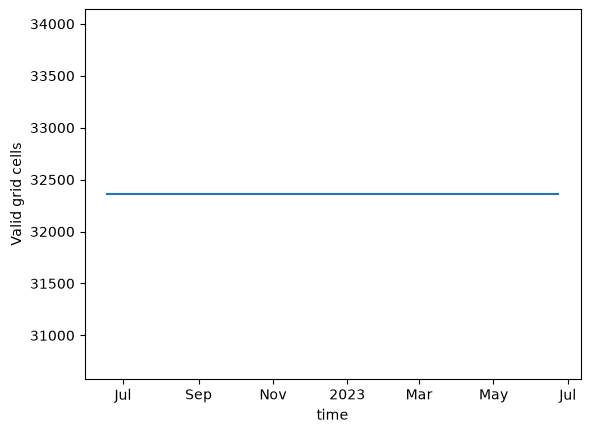

In [62]:
%%time
diff["diff"].count(["lat", "lon"]).rename("Valid grid cells").plot()

In [63]:
%%time
diff.to_zarr(
    f"{target_root}/diff.zarr", mode="w", storage_options=storage_options, zarr_format=2
)

CPU times: user 406 ms, sys: 88.6 ms, total: 495 ms
Wall time: 384 ms


## 3. Represent candidate locations on an equal-area grid

We transfer the temperature comparisons to a grid called **HEALPix**. Each cell represents the same area of the Earth's surface. Its hierarchical structure lets us choose a finer or coarser grid; the refinement level 10 uses an approximate cell size of **3.2 km**.

This cell size is not the accuracy of the estimated fish location. Location uncertainty also depends on the observations, the ocean model, and the movement assumptions. Equal area does not imply identical cell shapes or eliminate all spatial distortion; see the [HEALPix documentation](https://healpix.sourceforge.io/) for details.

In [64]:
from pangeo_fish.helpers import (
    open_diff_dataset,
    regrid_dataset_hpresample,
)

In [65]:
# Open the previous dataset (only necessary if you resume the notebook from here)
diff = open_diff_dataset(target_root=target_root, storage_options=storage_options)
diff

<xarray.Dataset> Size: 223MB
Dimensions:     (yi: 198, xi: 252, time: 371)
Coordinates:
    latitude    (yi, xi) float32 200kB 46.03 46.03 46.03 ... 51.5 51.5 51.5
    longitude   (yi, xi) float32 200kB -6.999 -6.971 -6.944 ... -0.05448 -0.0267
  * time        (time) datetime64[ns] 3kB 2022-06-18 2022-06-19 ... 2023-06-23
Dimensions without coordinates: yi, xi
Data variables:
    H0          (yi, xi) float32 200kB dask.array<chunksize=(198, 252), meta=np.ndarray>
    XE          (time, yi, xi) float32 74MB dask.array<chunksize=(93, 50, 63), meta=np.ndarray>
    diff        (time, yi, xi) float64 148MB dask.array<chunksize=(47, 50, 63), meta=np.ndarray>
    ocean_mask  (yi, xi) bool 50kB dask.array<chunksize=(198, 252), meta=np.ndarray>
Attributes:
    acoustic_tag_id:           OPI-378
    comment:                   pangeo-fish == 2026.5.1.dev36+g1b8eac2a8.d2026...
    common_name:               Pollock
    history:                   {'Conventions': 'CF-1.8', 'comment': '', 'cont...
    pit_tag_id:                A18828
    project:                   FISHINTEL
    relative_depth_threshold:  0
    scientific_name:           Pollachius pollachius
    tag_name:                  A18828

In [66]:
reshaped, resampling_info = regrid_dataset_hpresample(
    ds=diff,
    refinement_level=refinement_level,
    ellipsoid=ellipsoid,
    dims=dims,
    mask_threshold=0.0,
)
reshaped

[KNeighborsResampler] dropping 2,659 retained cell(s) that passed the wide-neighbourhood 'threshold' test but were never selected by any sample's own Npt-nearest search (would otherwise silently read back as 0.0 for any input).
[CloughTocherResampler] N=32359 samples, 64256 Delaunay triangles, K=22899 output cells retained (inside convex hull).
ocean cells not covered by Clough-Tocher : 8531
iocean cells  not covered by CT nor by rewrap : 8151
H0 ('yi', 'xi')
XE ('time', 'yi', 'xi')
diff ('time', 'yi', 'xi')


<xarray.Dataset> Size: 188MB
Dimensions:     (cells: 31430, time: 371)
Coordinates:
    cell_ids    (cells) int64 251kB 2866879 2866927 ... 14499972 14499976
    latitude    (cells) float64 251kB 50.65 50.75 50.77 ... 51.52 51.52 51.52
    longitude   (cells) float64 251kB 0.02664 0.02671 0.02672 ... 353.2 353.1
  * time        (time) datetime64[ns] 3kB 2022-06-18 2022-06-19 ... 2023-06-23
    resolution  float64 8B 0.0004997
Dimensions without coordinates: cells
Data variables:
    ocean_mask  (cells) float64 251kB 1.0 1.0 1.0 1.0 1.0 ... 1.0 1.0 1.0 1.0
    H0          (cells) float64 251kB nan nan nan nan ... 80.19 80.59 79.45
    XE          (time, cells) float64 93MB nan nan nan ... -0.2768 -0.2874
    diff        (time, cells) float64 93MB nan nan nan ... 1.031 1.405 -1.128
Attributes:
    acoustic_tag_id:           OPI-378
    comment:                   pangeo-fish == 2026.5.1.dev36+g1b8eac2a8.d2026...
    common_name:               Pollock
    history:                   {'Conventions': 'CF-1.8', 'comment': '', 'cont...
    pit_tag_id:                A18828
    project:                   FISHINTEL
    relative_depth_threshold:  0
    scientific_name:           Pollachius pollachius
    tag_name:                  A18828
    grid_type:                 healpix
    level:                     11
    nside:                     2048

In [67]:
resampling_info["bbox"] = bbox
import json

# Save the regridding metadata and geographic bounds alongside the results.
with open(f"{target_root}/resampling_info.json", "w") as f:
    json.dump(resampling_info, f)

with open(f"{target_root}/resampling_info.json") as f:
    resampling_info = json.load(f)
resampling_info

{'resolution_2D': [198, 252],
 'refinement_level': 11,
 'ellipsoid': 'sphere',
 'bbox': {'latitude': [46, 51.5], 'longitude': [-7, 0]}}

Check data availability again after changing the grid. The number of cells may differ because their size and coverage have changed. Look for sudden drops, and investigate any time step with a count of zero before continuing.

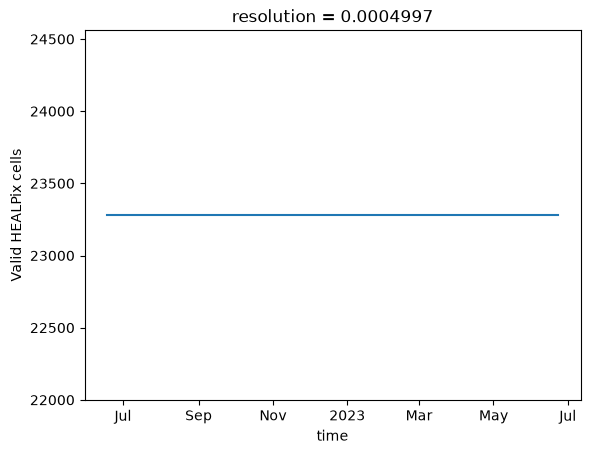

In [68]:
reshaped["diff"].count(dims).rename("Valid HEALPix cells").plot()

In [69]:
# Saves the result
reshaped.chunk(default_chunk_dims).to_zarr(
    f"{target_root}/diff-regridded.zarr",
    mode="w",
    consolidated=True,
    compute=True,
    storage_options=storage_options,
    zarr_format=2,
)

/home/cchauveau/micromamba/envs/pangeo-fish-pr262/lib/python3.11/site-packages/distributed/client.py:3429: UserWarning: Sending large graph of size 179.21 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


The following maps show temperature differences (`diff`) and model seabed depth (`H0`). On the temperature-difference map, look for values close to zero: are good matches concentrated in one area or spread across several areas? Check how this pattern changes over time.

In [70]:
reshaped.healpix.plot(var=["diff", "H0", "ocean_mask"], alpha=0.5)

## 4. Identify locations consistent with the temperatures

We give more weight to locations where model temperatures match the tag observations. These weights are called **emission likelihoods**: they describe how consistent the observations are with each candidate location.

We use a Gaussian curve centered on a temperature difference of zero. The setting `differences_std` controls its width: larger values allow a wider range of temperature differences. Release and recapture/death locations provide additional spatial constraints.

The temperature weights, stored as `emission_pdf["pdf"]`, do not yet sum to one across locations. We combine and normalize the evidence in Section 6.

In [71]:
from pangeo_fish.helpers import compute_emission_pdf

In [72]:
# Open the previous dataset (only necessary if you resume the notebook from here)
differences = xr.open_dataset(
    f"{target_root}/diff-regridded.zarr",
    engine="zarr",
    chunks={},
    storage_options=storage_options,
)

# ... and compute the emission matrices
emission_pdf = compute_emission_pdf(
    diff_ds=differences,
    events_ds=tag["tagging_events"].ds,
    differences_std=differences_std,
    initial_std=initial_std,
    recapture_std=recapture_std,
    dims=dims,
    chunk_time=chunk_time,
)[0]
emission_pdf

<xarray.Dataset> Size: 95MB
Dimensions:     (cells: 31430, time: 371)
Coordinates:
  * cell_ids    (cells) int64 251kB 2866879 2866927 ... 14499972 14499976
    latitude    (cells) float64 251kB dask.array<chunksize=(31430,), meta=np.ndarray>
    longitude   (cells) float64 251kB dask.array<chunksize=(31430,), meta=np.ndarray>
    resolution  float64 8B ...
  * time        (time) datetime64[ns] 3kB 2022-06-18 2022-06-19 ... 2023-06-23
Dimensions without coordinates: cells
Data variables:
    pdf         (time, cells) float64 93MB dask.array<chunksize=(1, 31430), meta=np.ndarray>
    initial     (cells) float64 251kB dask.array<chunksize=(31430,), meta=np.ndarray>
    final       (cells) float64 251kB dask.array<chunksize=(31430,), meta=np.ndarray>
    mask        (cells) float64 251kB dask.array<chunksize=(31430,), meta=np.ndarray>
Indexes:
    cell_ids  HealpixIndex(level=11, indexing_scheme=nested, kind=pandas)
Attributes: (12/15)
    acoustic_tag_id:           OPI-378
    comment:                   pangeo-fish == 2026.5.1.dev36+g1b8eac2a8.d2026...
    common_name:               Pollock
    grid_type:                 healpix
    history:                   {'Conventions': 'CF-1.8', 'comment': '', 'cont...
    level:                     11
    ...                        ...
    relative_depth_threshold:  0
    scientific_name:           Pollachius pollachius
    tag_name:                  A18828
    differences_std:           0.75
    recapture_std:             0.0001
    initial_std:               0.0001

Compare the temperature weights (`pdf`) with the release (`initial`) and final-location (`final`, when available) maps. Do the temperature observations identify a small area, or leave several possible regions?

In [73]:
emission_pdf.healpix.plot(["initial", "final", "pdf"])

Check the total temperature likelihood at each time step, `total = sum(dims, min_count=1)`. It need not equal one yet.

- `NaN`: no data at that time step.
- `0`: data exist, but no location matches the tag temperature.

If either appears, investigate it before continuing.

Time steps without data (NaN): 0
Time steps with zero total weight: 0


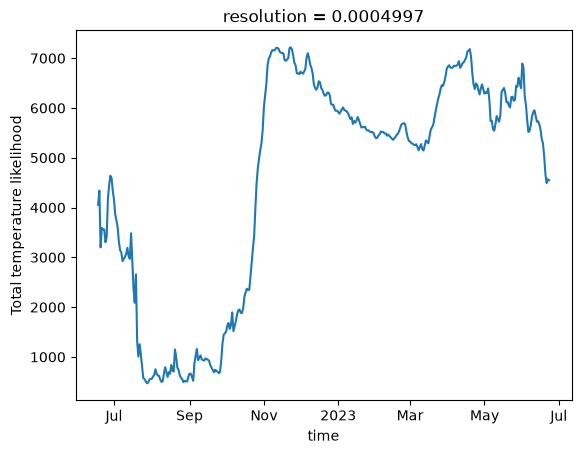

In [74]:
emission_pdf = emission_pdf.chunk(default_chunk_dims).persist()
total = (
    emission_pdf["pdf"].sum(dims, min_count=1).rename("Total temperature likelihood")
)
print("Time steps without data (NaN):", int(total.isnull().sum()))
print("Time steps with zero total weight:", int((total == 0).sum()))
total.plot()

In [75]:
# Save the dataset
emission_pdf.to_zarr(
    f"{target_root}/emission_diff.zarr",
    mode="w",
    consolidated=True,
    storage_options=storage_options,
    zarr_format=2,
)

In [76]:
emission_pdf.attrs["sources"] = emission_pdf.attrs.get("sources", []) + [
    "temperature"
]  # Record the evidence sources included so far.
emission_pdf.to_zarr(
    f"{target_root}/total_pdf.zarr",
    mode="w",
    consolidated=True,
    storage_options=storage_options,
    zarr_format=2,
)

## 5. Add information from acoustic detections

A detection tells us that the fish was within the assumed detection area of a receiver. We use this information to constrain its possible locations, complementing the temperature evidence.

This step requires acoustic detections and receiver locations in the tag data. The setting `receiver_buffer` defines the assumed detection range. We combine this evidence with temperature in Section 6.

In [77]:
from pangeo_fish.helpers import compute_acoustic_pdf

In [78]:
# Load the previous emission pdf and compute the emission probabilities based on acoustic detections
emission_diff = xr.open_dataset(
    f"{target_root}/emission_diff.zarr",
    engine="zarr",
    chunks={},
    storage_options=storage_options,
)

acoustic_pdf = compute_acoustic_pdf(
    emission_ds=emission_diff,
    tag=tag,
    receiver_buffer=receiver_buffer,
    chunk_time=chunk_time,
    dims=dims,
)[0]
acoustic_pdf = acoustic_pdf.persist()
acoustic_pdf

<xarray.Dataset> Size: 94MB
Dimensions:     (cells: 31430, time: 371)
Coordinates:
    longitude   (cells) float64 251kB 0.02664 0.02671 0.02672 ... 353.2 353.1
    latitude    (cells) float64 251kB 50.65 50.75 50.77 ... 51.52 51.52 51.52
    resolution  float64 8B 0.0004997
  * time        (time) datetime64[ns] 3kB 2022-06-18 2022-06-19 ... 2023-06-23
  * cell_ids    (cells) int64 251kB 2866879 2866927 ... 14499972 14499976
Dimensions without coordinates: cells
Data variables:
    acoustic    (time, cells) float64 93MB dask.array<chunksize=(1, 31430), meta=np.ndarray>
Indexes:
    cell_ids  HealpixIndex(level=11, indexing_scheme=nested, kind=pandas)
Attributes: (12/16)
    acoustic_tag_id:           OPI-378
    comment:                   pangeo-fish == 2026.5.1.dev36+g1b8eac2a8.d2026...
    common_name:               Pollock
    differences_std:           0.75
    grid_type:                 healpix
    history:                   {'Conventions': 'CF-1.8', 'comment': '', 'cont...
    ...                        ...
    project:                   FISHINTEL
    recapture_std:             0.0001
    relative_depth_threshold:  0
    scientific_name:           Pollachius pollachius
    tag_name:                  A18828
    receiver_buffer:           2000 meter

In [79]:
acoustic_pdf.healpix.plot("acoustic")

The following plot compares detection times with a cell-count diagnostic. Look for changes around detection times.

Here the code counts cells satisfying `acoustic != 0`. Missing values also satisfy this comparison, so this curve is not an exact count of possible fish locations. Keep this distinction in mind when interpreting it.

In [80]:
tag["acoustic"]["deployment_id"].hvplot.scatter(c="red", marker="x") * (
    acoustic_pdf["acoustic"] != 0
).sum(dim=dims).hvplot()

:Overlay
   .Scatter.I :Scatter   [time]   (deployment_id)
   .Curve.I   :Curve   [time]   (acoustic)

At detection times, the possible locations can narrow sharply to the areas around receivers, under the assumed detection range. These detections provide strong spatial constraints. Interpret changes in the curve alongside the detection times, rather than treating its height as an exact number of possible locations.

The next cell optionally saves the acoustic results separately. The following analysis can use the results already calculated.

In [81]:
acoustic_pdf.to_zarr(
    f"{target_root}/acoustic.zarr",
    mode="w",
    consolidated=True,
    storage_options=storage_options,
)

### Bring the evidence together

In [82]:
# Open the currently saved evidence sources.
current_total = xr.open_dataset(
    f"{target_root}/total_pdf.zarr",
    engine="zarr",
    chunks={},
    storage_options=storage_options,
)
current_total

<xarray.Dataset> Size: 95MB
Dimensions:     (cells: 31430, time: 371)
Coordinates:
    cell_ids    (cells) int64 251kB dask.array<chunksize=(31430,), meta=np.ndarray>
    latitude    (cells) float64 251kB dask.array<chunksize=(31430,), meta=np.ndarray>
    longitude   (cells) float64 251kB dask.array<chunksize=(31430,), meta=np.ndarray>
    resolution  float64 8B ...
  * time        (time) datetime64[ns] 3kB 2022-06-18 2022-06-19 ... 2023-06-23
Dimensions without coordinates: cells
Data variables:
    final       (cells) float64 251kB dask.array<chunksize=(31430,), meta=np.ndarray>
    initial     (cells) float64 251kB dask.array<chunksize=(31430,), meta=np.ndarray>
    mask        (cells) float64 251kB dask.array<chunksize=(31430,), meta=np.ndarray>
    pdf         (time, cells) float64 93MB dask.array<chunksize=(1, 31430), meta=np.ndarray>
Attributes: (12/16)
    acoustic_tag_id:           OPI-378
    comment:                   pangeo-fish == 2026.5.1.dev36+g1b8eac2a8.d2026...
    common_name:               Pollock
    differences_std:           0.75
    grid_type:                 healpix
    history:                   {'Conventions': 'CF-1.8', 'comment': '', 'cont...
    ...                        ...
    project:                   FISHINTEL
    recapture_std:             0.0001
    relative_depth_threshold:  0
    scientific_name:           Pollachius pollachius
    sources:                   ['temperature']
    tag_name:                  A18828

In [83]:
if "acoustic" in current_total.data_vars:
    pass
else:
    current_total = current_total.load()
    current_total.attrs["sources"] = current_total.attrs.get("sources", []) + [
        "acoustic"
    ]

    merged_pdf = current_total.merge(
        acoustic_pdf.drop_indexes(["cell_ids"]), compat="override"
    )

    merged_pdf.to_zarr(
        f"{target_root}/total_pdf.zarr",
        mode="w",
        consolidated=True,
        storage_options=storage_options,
        zarr_format=2,
    )
merged_pdf

<xarray.Dataset> Size: 188MB
Dimensions:     (cells: 31430, time: 371)
Coordinates:
    cell_ids    (cells) int64 251kB 2866879 2866927 ... 14499972 14499976
    latitude    (cells) float64 251kB 50.65 50.75 50.77 ... 51.52 51.52 51.52
    longitude   (cells) float64 251kB 0.02664 0.02671 0.02672 ... 353.2 353.1
    resolution  float64 8B 0.0004997
  * time        (time) datetime64[ns] 3kB 2022-06-18 2022-06-19 ... 2023-06-23
Dimensions without coordinates: cells
Data variables:
    final       (cells) float64 251kB 0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0
    initial     (cells) float64 251kB 0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0
    mask        (cells) float64 251kB 1.0 1.0 1.0 1.0 1.0 ... 1.0 1.0 1.0 1.0
    pdf         (time, cells) float64 93MB nan nan nan ... 0.2069 0.092 0.1716
    acoustic    (time, cells) float64 93MB dask.array<chunksize=(1, 31430), meta=np.ndarray>
Attributes: (12/16)
    acoustic_tag_id:           OPI-378
    comment:                   pangeo-fish == 2026.5.1.dev36+g1b8eac2a8.d2026...
    common_name:               Pollock
    differences_std:           0.75
    grid_type:                 healpix
    history:                   {'Conventions': 'CF-1.8', 'comment': '', 'cont...
    ...                        ...
    project:                   FISHINTEL
    recapture_std:             0.0001
    relative_depth_threshold:  0
    scientific_name:           Pollachius pollachius
    sources:                   ['temperature', 'acoustic']
    tag_name:                  A18828

## 6. Add information from Bathymetry

In this step, the goal is to calculate another emission distribution, this time using a bathymetry like GEBCO, EMODNET...

These additional probabilities will enhance the emission pdf constructed in the previous step by incorporating information from bathymetry information.

/!\ you must have run and save at least once chapter 2 and the "relative_depth_threshold" parameter have to be put at 0

### Data importation

Import the ocean reference model and diff which was calculated in chapter 2. Also import of the bathymetry database.

In [84]:
if "reference_model" in locals():
    pass
else:
    from pangeo_fish.helpers import load_model

    reference_model = load_model(
        uri=ref_url,
        tag_log=tag_log,
        time_slice=time_slice,
        bbox=(bbox | {"max_depth": tag_log["pressure"].max()}),
        chunk_time=chunk_time,
        remote_options={},
        copernicus_model_name=copernicus_model_name,
    )
emission_diff = xr.open_dataset(
    f"{target_root}/emission_diff.zarr",
    engine="zarr",
    chunks={},
    storage_options=storage_options,
)


In [91]:
import fsspec
import numpy as np
from pangeo_fish.cf import bounds_to_bins
from pangeo_fish.tags import adapt_model_time, reshape_by_bins, to_time_slice
from pangeo_fish.bathy import batch_compute_pdf_bathy
from pangeo_fish.bathy import (
    compute_healpix_histogram_region_bin_size,
)

# bathy_url is the path to the bathymetry file
bathy_url = "https://data-taos.ifremer.fr/global_bathy/GEBCO_2024.zarr"

nside = (2**refinement_level)  # parameter equivalent to refinement level used in some functions
full_bathy = xr.open_dataset(
    "https://data-taos.ifremer.fr/demo/database/gebco_2024_new.zarr/", 
    engine="zarr",
    chunks={},
    storage_options=None,
).rename({"lat": "latitude", "lon": "longitude"})
full_bathy

<xarray.Dataset> Size: 7GB
Dimensions:    (latitude: 43200, longitude: 86400)
Coordinates:
  * latitude   (latitude) float64 346kB -90.0 -89.99 -89.99 ... 89.99 89.99 90.0
  * longitude  (longitude) float64 691kB -180.0 -180.0 -180.0 ... 180.0 180.0
Data variables:
    crs        |S1 1B ...
    elevation  (latitude, longitude) int16 7GB dask.array<chunksize=(1000, 1000), meta=np.ndarray>
Attributes: (12/36)
    Conventions:                     CF-1.6, ACDD-1.3
    comment:                         The data in the GEBCO_2024 Grid should n...
    creator_email:                   gdacc@seabed2030.org
    creator_name:                    GEBCO through the Nippon Foundation-GEBC...
    creator_type:                    International organisation
    creator_url:                     https://www.gebco.net
    ...                              ...
    node_offset:                     1.0
    project:                         Nippon Foundation - GEBCO Seabed2030 Pro...
    references:                      DOI: 10.5285/1c44ce99-0a0d-5f4f-e063-708...
    source:                          The GEBCO_2024 Grid is the 2024 release ...
    summary:                         The GEBCO_2024 Grid is a continuous, glo...
    title:                           The GEBCO_2024 Grid - a continuous terra...

In [92]:
subset_bathy = full_bathy.sel(
    {dim: slice(bounds[0] - 0.1, bounds[1] + 0.1) for dim, bounds in bbox.items()}
)


In [93]:
ds_histo = compute_healpix_histogram_region_bin_size(
    subset_bathy,
    nside=nside,
    max_depth_m=1000,  # <- max depth in meters
    depth_bin_size=16,  # <- bin width in meters
    ellipsoid=ellipsoid,
)

Pass 2 – compute histogram: 100%|██████████| 3/3 [00:01<00:00,  2.96it/s]


Compute the pdf

In [94]:
from pangeo_fish.bathy import batch_compute_pdf_bathy

reshaped_tag = reshape_by_bins(  # reshape the tags for the calculation of the pdf
    tag_log,
    dim="time",
    bins=(
        reference_model.cf.add_bounds(["time"], output_dim="bounds")
        .pipe(bounds_to_bins, bounds_dim="bounds")
        .get("time_bins")
    ),
    other_dim="obs",
).chunk({"time": chunk_time})

pdf_da_func = batch_compute_pdf_bathy(
    ds_histo,
    reshaped_tag,
    target_root,
    batch_size=10000,
)

sum_over_cells = pdf_da_func.sum(dim="cells", skipna=True)
bathy_pdf = pdf_da_func / sum_over_cells #normalization
bathy_pdf

Batch cells 0–10000
Batch cells 10000–20000
Batch cells 20000–30000
Batch cells 30000–31430


<xarray.Dataset> Size: 94MB
Dimensions:    (time: 371, cells: 31430)
Coordinates:
  * time       (time) datetime64[ns] 3kB 2022-06-18 2022-06-19 ... 2023-06-23
  * cell_ids   (cells) int64 251kB 2866879 2866927 2866938 ... 14499972 14499976
Dimensions without coordinates: cells
Data variables:
    pdf_bathy  (time, cells) float64 93MB nan nan nan ... 4.347e-05 4.347e-05

The next cell optionally saves the bathymetric results separately. The following analysis can use the results already calculated.

In [95]:
bathy_pdf.compute().to_zarr(
    f"{target_root}/bathy_pdf_{tag_name}.zarr",
    compute=True,
    mode="w",
    consolidated=True,
    zarr_version=2,
    storage_options=storage_options,
)


/tmp/ipykernel_7979/928099791.py:1: FutureWarning: zarr_version is deprecated, use zarr_format
  bathy_pdf.compute().to_zarr(


In [96]:
# If you want to see the pdf
bathy_pdf.healpix.plot("pdf_bathy",refinement_level=11)

### Bring the evidence together

In [97]:
## Open the dataset with the other pdfs
current_total = xr.open_dataset(
    f"{target_root}/total_pdf.zarr",
    engine="zarr",
    chunks={},
    storage_options=storage_options,
)

In [98]:
if "pdf_bathy" in current_total.data_vars:
    pass
else:
    current_total = current_total.load()
    current_total.attrs["sources"] = list(
        set(current_total.attrs.get("sources", [])) | {"bathymétrie"}
    )
    merged_pdf = current_total.merge(
        bathy_pdf.drop_indexes(["cell_ids"]), compat="override"
    )

    merged_pdf.to_zarr(
        f"{target_root}/total_pdf.zarr",
        mode="w",
        consolidated=True,
        storage_options=storage_options,
        zarr_format=2,
    )
merged_pdf

<xarray.Dataset> Size: 281MB
Dimensions:     (time: 371, cells: 31430)
Coordinates:
    cell_ids    (cells) int64 251kB 2866879 2866927 ... 14499972 14499976
    latitude    (cells) float64 251kB 50.65 50.75 50.77 ... 51.52 51.52 51.52
    longitude   (cells) float64 251kB 0.02664 0.02671 0.02672 ... 353.2 353.1
    resolution  float64 8B 0.0004997
  * time        (time) datetime64[ns] 3kB 2022-06-18 2022-06-19 ... 2023-06-23
Dimensions without coordinates: cells
Data variables:
    acoustic    (time, cells) float64 93MB 3.182e-05 3.182e-05 ... 3.186e-05
    final       (cells) float64 251kB 0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0
    initial     (cells) float64 251kB 0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0
    mask        (cells) float64 251kB 1.0 1.0 1.0 1.0 1.0 ... 1.0 1.0 1.0 1.0
    pdf         (time, cells) float64 93MB nan nan nan ... 0.2069 0.092 0.1716
    pdf_bathy   (time, cells) float64 93MB nan nan nan ... 4.347e-05 4.347e-05
Attributes: (12/16)
    acoustic_tag_id:           OPI-378
    comment:                   pangeo-fish == 2026.5.1.dev36+g1b8eac2a8.d2026...
    common_name:               Pollock
    differences_std:           0.75
    grid_type:                 healpix
    history:                   {'Conventions': 'CF-1.8', 'comment': '', 'cont...
    ...                        ...
    project:                   FISHINTEL
    recapture_std:             0.0001
    relative_depth_threshold:  0
    scientific_name:           Pollachius pollachius
    sources:                   ['acoustic', 'bathymétrie', 'temperature']
    tag_name:                  A18828

In [99]:
liste = multiplot_healpix(
    [(merged_pdf, ["acoustic", "pdf", "pdf_bathy"])],
)

multi_map_with_synced_sliders(liste)

## 7. Add information from Tide
In this step, the goal is to calculate another emission distribution based on tide.

First we detect tide, then we try to observe a behavior on the data



In [100]:
from pangeo_fish.tide import *
import xarray as xr
import pandas as pd
import numpy as np

0         0 days 00:00:00
1         0 days 00:10:00
2         0 days 00:20:00
3         0 days 00:30:00
4         0 days 00:40:00
               ...       
53420   370 days 23:20:00
53421   370 days 23:30:00
53422   370 days 23:40:00
53423   370 days 23:50:00
53424   371 days 00:00:00
Name: time, Length: 53425, dtype: timedelta64[ns]
60
Extraction du signal de marée (10 h)...


100%|██████████| 53365/53365 [00:35<00:00, 1488.05it/s]


Classification comportementale (16 h)...


100%|██████████| 53329/53329 [00:36<00:00, 1466.25it/s]



Extraction terminée ✅


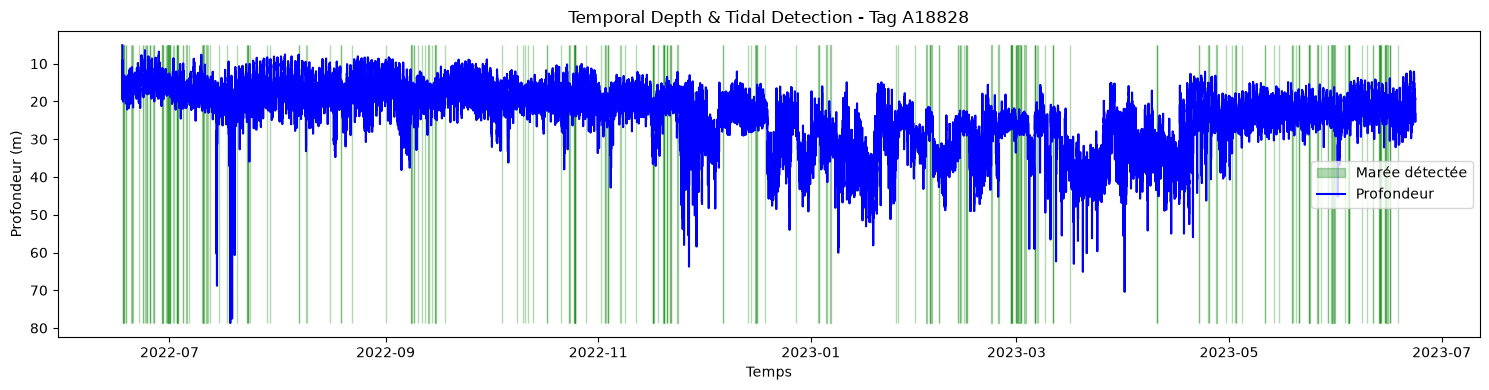

<xarray.Dataset> Size: 4MB
Dimensions:      (time: 53425)
Coordinates:
  * time         (time) datetime64[ns] 427kB 2022-06-17T10:50:00 ... 2023-06-...
Data variables:
    depth        (time) float64 427kB 5.12 19.5 11.93 8.31 ... 21.18 25.43 23.31
    rmse_tide    (time) float64 427kB 0.7597 0.7481 0.7362 ... nan nan nan
    rsq_tide     (time) float64 427kB 0.9513 0.9474 0.9466 0.948 ... nan nan nan
    ampli_tide   (time) float64 427kB 3.605 3.603 3.727 3.708 ... nan nan nan
    tide_found   (time) int64 427kB 0 0 0 0 0 0 0 0 0 0 ... 0 0 0 0 0 0 0 0 0 0
    rmse_behav   (time) float64 427kB 1.561 1.57 1.64 1.612 ... nan nan nan nan
    rsq_behav    (time) float64 427kB 0.7043 0.6649 0.6207 ... nan nan nan
    ampli_behav  (time) float64 427kB 2.549 2.513 2.518 2.478 ... nan nan nan
    behav_found  (time) int64 427kB 0 0 0 0 0 0 0 0 0 0 ... 0 0 0 0 0 0 0 0 0 0
Attributes:
    tagno:    A18828
    tideFL:   10
    tideLV:   [0.42, 0.85, 0.6]
    behavFL:  16
    behavLV:  [0.42, 0.7, 0.2]
    dt:       10

In [101]:
tag_test = detect_tide(tag_log, tag_name)
plot_tide(tag_test)
tag_test


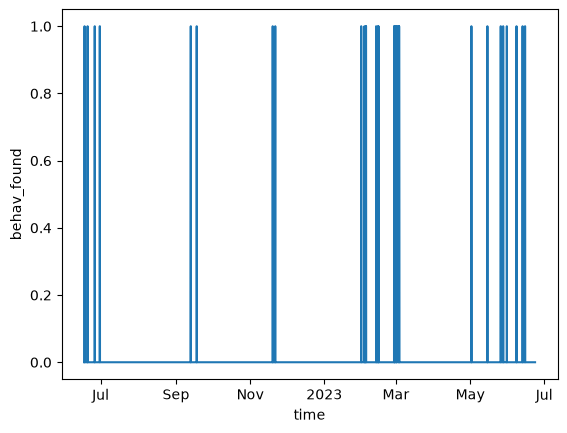

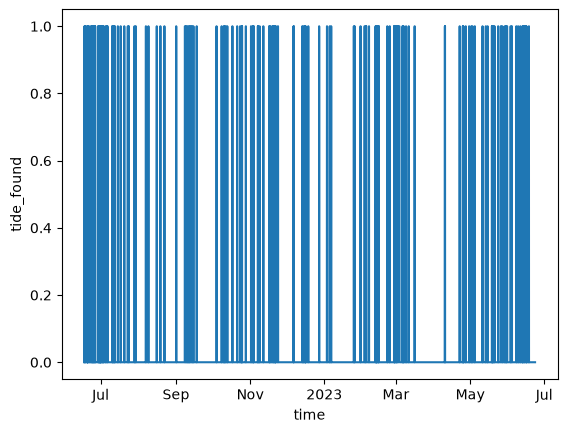

In [111]:
tag_test.to_zarr(
    f"{target_root}/tide_behav.zarr",
    mode="w",
    consolidated=True,
    storage_options=storage_options,
    zarr_format=2,
)
tide_behav = xr.open_dataset(f"{target_root}/tide_behav.zarr", engine="zarr")
tide_behav["behav_found"].plot()
plt.figure()
tide_behav["tide_found"].plot()

### Import Tide database

In [112]:
import requests

url = "https://data-taos.ifremer.fr/demo/database/Subset_NS_EC_forTMD30_21_2_2025.nc"

# download the file
print("Téléchargement...")
r = requests.get(url)
with open("Subset_NS_EC_forTMD30_21_2_2025.nc", "wb") as f:
    f.write(r.content)

# Open with xarray
print("Opening...")
data_360 = xr.open_dataset("Subset_NS_EC_forTMD30_21_2_2025.nc")
data = convert_lon_360_to_180(
    data_360, bbox
)  # conversion in the good system of coordinates
data

Téléchargement...
Opening...
46 51.5
here
51.500003814697266
slice(46, 51.500003814697266, None)


<xarray.Dataset> Size: 26MB
Dimensions:       (lon: 211, lat: 166, constituents: 15)
Coordinates:
  * lat           (lat) float32 664B 46.0 46.03 46.07 46.1 ... 51.43 51.47 51.5
  * constituents  (constituents) int8 15B 1 2 3 4 5 6 7 8 9 10 11 12 13 14 15
  * lon           (lon) float32 844B -7.0 -6.967 -6.933 ... -0.03333 0.0
Data variables: (12/13)
    mapping       (lon) |S8 2kB ...
    wct           (lat, lon) float32 140kB ...
    mask          (lat, lon) float32 140kB ...
    amplitude     (constituents, lon) float64 25kB ...
    phase         (constituents, lon) float64 25kB ...
    omega         (constituents, lon) float32 13kB ...
    ...            ...
    hRe           (constituents, lat, lon) float64 4MB ...
    hIm           (constituents, lat, lon) float64 4MB ...
    URe           (constituents, lat, lon) float64 4MB ...
    UIm           (constituents, lat, lon) float64 4MB ...
    VRe           (constituents, lat, lon) float64 4MB ...
    VIm           (constituents, lat, lon) float64 4MB ...
Attributes:
    Conventions:        CF-1.7
    Title:              TPXO9_atlas_v5
    Description:        Global tide model at 1/30 degree resolution.
    Author:             Egbert, Gary D., and Svetlana Y. Erofeeva.
    creation_date:      2025-02-19
    tmd_version:        3.0
    NetCDF_conversion:  Chad A. Greene
    model_type:         ocean
    license:            ask
    Data_citation:      Egbert, Gary D., and Svetlana Y. Erofeeva. "Efficient...

In [113]:
ds_pdf = tide_pdf(tide_behav, data)

# Save in zarr
ds_pdf.to_zarr(
    f"{target_root}/tide_pdf.zarr",
    mode="w",
    consolidated=True,
    storage_options=storage_options,
    zarr_format=2,
)

TypeError: 'Dataset' object is not callable

In [114]:
ds_pdf

<xarray.Dataset> Size: 2GB
Dimensions:      (time: 8905, latitude: 166, longitude: 211)
Coordinates:
    instant      (time) float64 71kB 0.0 1.0 2.0 ... 8.903e+03 8.904e+03
  * latitude     (latitude) float32 664B 46.0 46.03 46.07 ... 51.43 51.47 51.5
  * longitude    (longitude) float32 844B -7.0 -6.967 -6.933 ... -0.03333 0.0
  * time         (time) datetime64[ns] 71kB 2022-06-17T10:00:00 ... 2023-06-2...
Data variables:
    pdf          (time, latitude, longitude) float64 2GB 4.248e-05 ... 1e-200
    mask         (latitude, longitude) bool 35kB True True True ... False False
    tide_found   (time) int64 71kB 0 0 0 0 0 1 1 1 1 1 1 ... 0 0 0 0 0 0 0 0 0 0
    behav_found  (time) int64 71kB 0 0 0 0 0 0 1 1 1 0 0 ... 0 0 0 0 0 0 0 0 0 0

### Healpix regridding

In [115]:
tide_pdf, tide_found_daily, behav_found_daily = tide_to_healpix(target_root, refinement_level, ellipsoid)

Processing time chunk [0:2000] / 8905
[KNeighborsResampler] dropping 2,724 retained cell(s) that passed the wide-neighbourhood 'threshold' test but were never selected by any sample's own Npt-nearest search (would otherwise silently read back as 0.0 for any input).
[CloughTocherResampler] N=23539 samples, 46689 Delaunay triangles, K=23672 output cells retained (inside convex hull).
ocean cells not covered by Clough-Tocher : 471
iocean cells  not covered by CT nor by rewrap : 103
behav_found ('time',)
pdf ('time', 'yi', 'xi')
tide_found ('time',)
Processing time chunk [2000:4000] / 8905
[KNeighborsResampler] dropping 2,724 retained cell(s) that passed the wide-neighbourhood 'threshold' test but were never selected by any sample's own Npt-nearest search (would otherwise silently read back as 0.0 for any input).
[CloughTocherResampler] N=23539 samples, 46689 Delaunay triangles, K=23672 output cells retained (inside convex hull).
ocean cells not covered by Clough-Tocher : 471
iocean cells 

/home/cchauveau/micromamba/envs/pangeo-fish-pr262/lib/python3.11/site-packages/distributed/client.py:3429: UserWarning: Sending large graph of size 91.17 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(
/home/cchauveau/micromamba/envs/pangeo-fish-pr262/lib/python3.11/site-packages/distributed/client.py:3429: UserWarning: Sending large graph of size 91.17 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(
/home/cchauveau/micromamba/envs/pangeo-fish-pr262/lib/python3.11/site-packages/distributed/client.py:3429: UserW

DONE


In [116]:
tide_pdf.healpix.plot("pdf")

/home/cchauveau/micromamba/envs/pangeo-fish-pr262/lib/python3.11/site-packages/distributed/client.py:3429: UserWarning: Sending large graph of size 91.89 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


In [117]:
tide_pdf

<xarray.Dataset> Size: 192MB
Dimensions:     (time: 376, cells: 31778)
Coordinates:
    cell_ids    (cells) int64 254kB dask.array<chunksize=(31778,), meta=np.ndarray>
    latitude    (cells) float64 254kB dask.array<chunksize=(31778,), meta=np.ndarray>
    longitude   (cells) float64 254kB dask.array<chunksize=(31778,), meta=np.ndarray>
    resolution  float64 8B 0.0004997
  * time        (time) datetime64[ns] 3kB 2022-06-17 2022-06-18 ... 2023-06-23
Dimensions without coordinates: cells
Data variables:
    ocean_mask  (time, cells) float64 96MB dask.array<chunksize=(10, 31778), meta=np.ndarray>
    pdf         (time, cells) float64 96MB dask.array<chunksize=(10, 31778), meta=np.ndarray>
Attributes:
    grid_type:  healpix
    level:      11
    nside:      2048

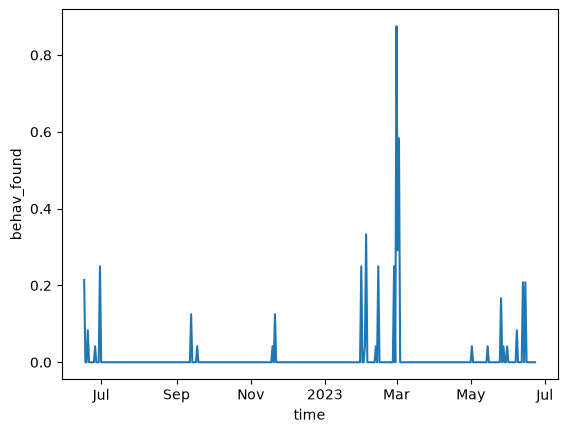

In [118]:
behav_found_daily.plot()

### Merge with other pdfs

In [120]:
emission_with_tide, tide_mask, behav_mask = merge_tide_with_total(target_root, storage_options)

In [121]:

emission_with_tide.to_zarr(
    f"{target_root}/total_pdf.zarr",
    mode="w",
    consolidated=True,
    storage_options=storage_options,
    zarr_format=2,
)
emission_with_tide

/home/cchauveau/micromamba/envs/pangeo-fish-pr262/lib/python3.11/site-packages/distributed/client.py:3429: UserWarning: Sending large graph of size 268.50 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


<xarray.Dataset> Size: 375MB
Dimensions:     (time: 371, cells: 31428)
Coordinates:
    cell_ids    (cells) int64 251kB dask.array<chunksize=(31428,), meta=np.ndarray>
    latitude    (cells) float64 251kB dask.array<chunksize=(31428,), meta=np.ndarray>
    longitude   (cells) float64 251kB dask.array<chunksize=(31428,), meta=np.ndarray>
    resolution  float64 8B 0.0004997
  * time        (time) datetime64[ns] 3kB 2022-06-18 2022-06-19 ... 2023-06-23
Dimensions without coordinates: cells
Data variables:
    pdf_tide    (time, cells) float64 93MB dask.array<chunksize=(3, 31428), meta=np.ndarray>
    acoustic    (time, cells) float64 93MB dask.array<chunksize=(3, 31428), meta=np.ndarray>
    final       (cells) float64 251kB dask.array<chunksize=(31428,), meta=np.ndarray>
    initial     (cells) float64 251kB dask.array<chunksize=(31428,), meta=np.ndarray>
    mask        (cells) float64 251kB dask.array<chunksize=(31428,), meta=np.ndarray>
    pdf         (time, cells) float64 93MB dask.array<chunksize=(3, 31428), meta=np.ndarray>
    pdf_bathy   (time, cells) float64 93MB dask.array<chunksize=(3, 31428), meta=np.ndarray>
Attributes: (12/16)
    acoustic_tag_id:           OPI-378
    comment:                   pangeo-fish == 2026.5.1.dev36+g1b8eac2a8.d2026...
    common_name:               Pollock
    differences_std:           0.75
    grid_type:                 healpix
    history:                   {'Conventions': 'CF-1.8', 'comment': '', 'cont...
    ...                        ...
    project:                   FISHINTEL
    recapture_std:             0.0001
    relative_depth_threshold:  0
    scientific_name:           Pollachius pollachius
    sources:                   ['acoustic', 'pdf_tide', 'bathymétrie', 'tempe...
    tag_name:                  A18828

## 8. Combine the distributions

We multiply the different probabilty density functions and include the final-location information when available. We then divide by the total weight across cells so that the combined values sum to one at each time step. This is called **normalization**.

The result describes the relative support for candidate locations from the observations. We still need the movement model to connect locations over time.

In [122]:
from pangeo_fish.helpers import combine_pdfs
from pangeo_fish.helpers import normalize_pdf

In [123]:
current_total = xr.open_dataset(
    f"{target_root}/total_pdf.zarr",
    engine="zarr",
    chunks={},
    storage_options=storage_options,
)
current_total

<xarray.Dataset> Size: 375MB
Dimensions:     (time: 371, cells: 31428)
Coordinates:
    cell_ids    (cells) int64 251kB dask.array<chunksize=(31428,), meta=np.ndarray>
    latitude    (cells) float64 251kB dask.array<chunksize=(31428,), meta=np.ndarray>
    longitude   (cells) float64 251kB dask.array<chunksize=(31428,), meta=np.ndarray>
    resolution  float64 8B ...
  * time        (time) datetime64[ns] 3kB 2022-06-18 2022-06-19 ... 2023-06-23
Dimensions without coordinates: cells
Data variables:
    acoustic    (time, cells) float64 93MB dask.array<chunksize=(3, 31428), meta=np.ndarray>
    final       (cells) float64 251kB dask.array<chunksize=(31428,), meta=np.ndarray>
    initial     (cells) float64 251kB dask.array<chunksize=(31428,), meta=np.ndarray>
    mask        (cells) float64 251kB dask.array<chunksize=(31428,), meta=np.ndarray>
    pdf         (time, cells) float64 93MB dask.array<chunksize=(3, 31428), meta=np.ndarray>
    pdf_bathy   (time, cells) float64 93MB dask.array<chunksize=(3, 31428), meta=np.ndarray>
    pdf_tide    (time, cells) float64 93MB dask.array<chunksize=(3, 31428), meta=np.ndarray>
Attributes: (12/16)
    acoustic_tag_id:           OPI-378
    comment:                   pangeo-fish == 2026.5.1.dev36+g1b8eac2a8.d2026...
    common_name:               Pollock
    differences_std:           0.75
    grid_type:                 healpix
    history:                   {'Conventions': 'CF-1.8', 'comment': '', 'cont...
    ...                        ...
    project:                   FISHINTEL
    recapture_std:             0.0001
    relative_depth_threshold:  0
    scientific_name:           Pollachius pollachius
    sources:                   ['acoustic', 'pdf_tide', 'bathymétrie', 'tempe...
    tag_name:                  A18828

In [124]:
emission_pdf = normalize_pdf(
    ds=current_total,
    chunks=default_chunk_dims,
    dims=dims,
    exclude=("initial", "final", "mask"),
    excluded_pdf=None,  # ("acoustic",),
)[0]

emission_pdf.to_zarr(
    f"{target_root}/combined.zarr",
    mode="w",
    consolidated=True,
    storage_options=storage_options,
    zarr_format=2,
)
combined = emission_pdf

emission_pdf["pdf"].sum(dims).hvplot(
    width=500, ylim=(0, 2), title="Total probability per time step"
)

/home/cchauveau/pangeo-fish-1106/pangeo-fish/pangeo_fish/helpers.py:1509: UserWarning: you decided to normalize the pdf without: None, if you want to include them, change excluded_pdf 
  warnings.warn(


:Curve   [time]   (pdf)

The total probability should be approximately **1** at every time step. A time step with no data also shows up as a departure from 1 (its sum is 0). Investigate any such time step before fitting the movement model.

In [125]:
combined.healpix.plot("pdf")

## 9. Estimate how widely the fish can move

The movement model connects possible fish locations between successive time steps. Its parameter, `sigma`, controls how widely movement can spread: larger values allow a broader range of displacements. We estimate this parameter from the observations.

Run the following cells to fit and save the movement parameter. Check that the search finishes without warnings. The printed `f(x)` values measure the fit at trial values of `sigma`; they need not improve at every step while the search explores different values.

The movement time interval comes from the dates in the data. Changing the video setting `time_step` does not change fish movement in the model.

<details>
<summary>Optional: how the parameter search works</summary>

The search uses Brent's method between `1e-4` radians and an upper bound of `maximum_speed × Δt × adjustment_factor / earth_radius`, where Δt is the interval in the emission time coordinate and `earth_radius` is derived from the ellipsoid stored with the HEALPix grid (about 6371 km for `"sphere"`). The speed setting bounds the search for `sigma`; it is not a strict limit on every possible displacement.

Check whether the fitted value is near a search bound. Successful convergence does not establish that the solution is unique or the global optimum. The appendix allows comparison with alternative values. The fitted parameters and calculation settings are saved in a JSON file for the next step.

</details>

In [126]:
from pangeo_fish.helpers import optimize_pdf

In [127]:
# Open the distributions
emission = xr.open_dataset(
    f"{target_root}/combined.zarr",
    engine="zarr",
    chunks=default_chunk_dims,
    inline_array=True,
    storage_options=storage_options,
)
emission

<xarray.Dataset> Size: 95MB
Dimensions:     (cells: 31428, time: 371)
Coordinates:
    cell_ids    (cells) int64 251kB dask.array<chunksize=(31428,), meta=np.ndarray>
    latitude    (cells) float64 251kB dask.array<chunksize=(31428,), meta=np.ndarray>
    longitude   (cells) float64 251kB dask.array<chunksize=(31428,), meta=np.ndarray>
    resolution  float64 8B ...
  * time        (time) datetime64[ns] 3kB 2022-06-18 2022-06-19 ... 2023-06-23
Dimensions without coordinates: cells
Data variables:
    final       (cells) float64 251kB dask.array<chunksize=(31428,), meta=np.ndarray>
    initial     (cells) float64 251kB dask.array<chunksize=(31428,), meta=np.ndarray>
    mask        (cells) float64 251kB dask.array<chunksize=(31428,), meta=np.ndarray>
    pdf         (time, cells) float64 93MB dask.array<chunksize=(1, 31428), meta=np.ndarray>
Attributes: (12/16)
    acoustic_tag_id:           OPI-378
    comment:                   pangeo-fish == 2026.5.1.dev36+g1b8eac2a8.d2026...
    common_name:               Pollock
    differences_std:           0.75
    grid_type:                 healpix
    history:                   {'Conventions': 'CF-1.8', 'comment': '', 'cont...
    ...                        ...
    project:                   FISHINTEL
    recapture_std:             0.0001
    relative_depth_threshold:  0
    scientific_name:           Pollachius pollachius
    sources:                   ['acoustic', 'pdf_tide', 'bathymétrie', 'tempe...
    tag_name:                  A18828

In [128]:
# Define the parameter's bounds and search for the best value
params = optimize_pdf(
    ds=emission,
    adjustment_factor=adjustment_factor,
    truncate=truncate,
    maximum_speed=maximum_speed,
    tolerance=1e-6,  # tolerance,
    dims=dims,
    # the results can be directly saved
    save_parameters=True,
    storage_options=storage_options,
    target_root=f"{target_root}",
    conv_method="LargeHealpixConv",  # fast multi-resolution convolution; "HealpixConv" is the slower reference method
)
params

 
 Func-count     x          f(x)          Procedure
    1     0.00365904      3381.43        initial
    2     0.00585864      3381.74        golden
    3     0.00229961      3329.71        golden
    4     0.00145943      3290.46        golden
    5    0.000940175      3288.83        golden
    6      0.0011508      3288.83        parabolic
    7     0.00104549      3288.83        parabolic
    8     0.00100526      3288.83        golden
    9    0.000980401      3288.83        golden
   10    0.000965036      3288.83        golden
   11     0.00095554      3288.83        golden
   12    0.000949671      3288.83        golden
   13    0.000946043      3288.83        golden
   14    0.000943802      3288.83        golden
   15    0.000942416      3288.83        golden
   16     0.00094156      3288.83        golden
   17    0.000941031      3288.83        golden
   18    0.000940697      3288.83        golden

Optimization terminated successfully;
The returned value satisfies the term

({'sigma': [0.0009406974444232092],
  'predictors': None,
  'predictor_factory': {'class': "<class 'pangeo_fish.hmm.prediction.UpDownGaussian1DHealpix'>",
   'kwargs': {'grid_info': "HealpixInfo(level=11, ellipsoid='sphere', indexing_scheme='nested')",
    'sigma': 'None',
    'kernel_sz': 'None',
    'max_compact_kernel_sz': '7',
    'ellipsoid': 'sphere',
    'device': 'cpu',
    'dtype': 'torch.float32'}},
  'comment': 'pangeo-fish == 2026.5.1.dev36+g1b8eac2a8.d20261005, healpix-convolution == 0.1.2, xarray == 2025.3.1, xhealpixify == 2025.3.3'},
 <xarray.Dataset> Size: 95MB
 Dimensions:     (cells: 31428, time: 371)
 Coordinates:
   * cell_ids    (cells) int64 251kB 2866879 2866927 ... 14499972 14499976
     latitude    (cells) float64 251kB 50.65 50.75 50.77 ... 51.52 51.52 51.52
     longitude   (cells) float64 251kB 0.02664 0.02671 0.02672 ... 353.2 353.1
     resolution  float64 8B 0.0004997
   * time        (time) datetime64[ns] 3kB 2022-06-18 2022-06-19 ... 2023-06-23
 Dimens

## 10. Estimate locations and summarize tracks

We combine the observational evidence with the fitted movement model to estimate a probability for each candidate location over time. We summarize these distributions in two ways:

- **`mean`:** the mean location at each time step.
- **`mode`:** the cell with the highest probability at each time step.

These lines summarize the estimated distributions; they are not directly observed paths. When interpreting them, also examine how widely the probability is spread across the map. We calculate distance between successive track points in kilometres and the corresponding speed in kilometres per hour.

<details>
<summary>Optional: other track methods and measurements</summary>

Viterbi seeks the most probable complete sequence of locations, rather than a separate summary at each time step.

The `additional_track_quantities` setting accepts only `"speed"` and `"distance"`. Afterward, MovingPandas can calculate acceleration (`add_acceleration`), direction (`add_direction`), changes in direction (`add_angular_difference`), and time intervals (`add_timedelta`) from the returned trajectories. These are separate processing steps; see the [MovingPandas trajectory API](https://movingpandas.readthedocs.io/en/main/api/trajectory.html).

</details>

In [129]:
from pangeo_fish.helpers import predict_positions

In [130]:
states, trajectories = predict_positions(
    target_root=f"{target_root}",
    storage_options=storage_options,
    chunks=default_chunk_dims,
    track_modes=track_modes,
    additional_track_quantities=additional_track_quantities,
    save=True,
)

/home/cchauveau/micromamba/envs/pangeo-fish-pr262/lib/python3.11/site-packages/distributed/client.py:3429: UserWarning: Sending large graph of size 89.47 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(
/home/cchauveau/micromamba/envs/pangeo-fish-pr262/lib/python3.11/site-packages/distributed/client.py:3429: UserWarning: Sending large graph of size 89.51 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(
/home/cchauveau/micromamba/envs/pangeo-fish-pr262/lib/python3.11/site-packages/distributed/client.py:3429: UserW

The probabilities in `states` should sum to approximately **1** at each time step. A departure from 1 means missing or invalid values at that time step.

In [131]:
states["states"].sum(dims).hvplot(
    width=500, ylim=(0, 2), title="Total probability per time step"
)

/home/cchauveau/micromamba/envs/pangeo-fish-pr262/lib/python3.11/site-packages/distributed/client.py:3429: UserWarning: Sending large graph of size 88.98 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


:Curve   [time]   (states)

## 11. Explore the maps and tracks

Compare the mean and mode tracks, and inspect the probability maps over time. Where is the fish's location tightly constrained, and where are several areas plausible?

The **emission** maps show support from the observations. The **state** maps also account for movement between time steps. Compare their patterns to see how the movement model affects the estimated locations.

### 11.1 Compare the tracks

Where do the mean and mode tracks agree or differ? Use the probability maps to interpret these differences.

In [132]:
from pangeo_fish.helpers import plot_trajectories

plot_trajectories(
    target_root=f"{target_root}",
    track_modes=track_modes,
    storage_options=storage_options,
    save_html=True,
)

:Layout
   .Overlay.I  :Overlay
      .WMTS.I   :WMTS   [Longitude,Latitude]
      .Path.I   :Path   [Longitude,Latitude]   (speed)
      .Points.I :Points   [Longitude,Latitude]   (speed,triangle_angle)
   .Overlay.II :Overlay
      .WMTS.I   :WMTS   [Longitude,Latitude]
      .Path.I   :Path   [Longitude,Latitude]   (speed)
      .Points.I :Points   [Longitude,Latitude]   (speed,triangle_angle)

### 11.2 View the probability distributions over time

In [ ]:
from pangeo_fish.helpers import open_distributions, render_distributions

In [ ]:
data = open_distributions(
    target_root=target_root,
    storage_options=storage_options,
    chunks=default_chunk_dims,
    chunk_time=chunk_time,
)
data

The output above is a summary of the data available for plotting. Run the following cells to create an MP4 animation and play it directly below the code.

`time_step = 1` requests a frame at every data time step; `3` requests every third step. This changes only the video sampling. The current video tool omits the final time step, even when this setting is 1.

Watch for periods when the possible locations narrow or spread out, and compare these with the acoustic detection times.

In [ ]:
import numpy as np

lon = data["longitude"].values  # (nx,)
lat = data["latitude"].values  # (ny,)
lon_2d, lat_2d = np.meshgrid(
    lon, lat
)  # (ny, nx), two-dimensional geographic coordinates

data_2d = data.rename({"latitude": "y", "longitude": "x"})
data_2d = data_2d.assign_coords(
    longitude=(("y", "x"), lon_2d),
    latitude=(("y", "x"), lat_2d),
)
data_2d

In [ ]:
video_filename = render_distributions(
    data=data_2d,
    output_path=f"{target_root}/states",
    xlim=bbox["longitude"],
    ylim=bbox["latitude"],
    time_step=time_step,
    extension="mp4",
    frames_dir="video",
    remove_frames=True,
    storage_options=storage_options,
)

In [ ]:
from IPython.display import Video, display

display(Video(filename=video_filename, embed=True))

In [ ]:
print("Your results are in:", target_root)

## Optional appendix: compare movement assumptions

The main task is complete. To explore the influence of movement assumptions, the following cells compare the fitted model with two chosen values of `sigma`. Look at how the probability maps and tracks change.

Each comparison uses a separate output folder. Keep the supplied settings for a first comparison; more advanced analyses can also use different movement parameters over different time intervals.

In [ ]:
import json
import warnings
from pathlib import Path
import fsspec
from pangeo_fish.helpers import create_parameters, test_parameter
from pangeo_fish.helpers import optimize_pdf

First, copy the combined emission distribution into a separate output folder.

In [ ]:
# Open the distributions
emission = xr.open_dataset(
    f"{target_root}/combined.zarr",
    engine="zarr",
    chunks=default_chunk_dims,
    inline_array=True,
    storage_options=storage_options,
)
# Create a new folder
emission.to_zarr(
    f"{target_root}/hand_sigma/combined.zarr",  # replace "hand_sigma" by another name
    mode="w",
    consolidated=True,
    storage_options=storage_options,
    zarr_format=2,
)

Save the chosen movement parameters in the same folder.

In [ ]:
params = create_parameters(
    sigma=[0.002708796991645453],
    sigma_indices=None,
    class_name="UpDownGaussian1DHealpix",  # Convolution class for the movement model.
    target_root=f"{target_root}/hand_sigma",  # Match the folder used above.
    save_parameters=True,
)

Alternatively, `test_parameter()` saves the combined emission distribution and the chosen parameters in a comparison folder. Pass an existing dataset as `emission`, or leave it as `None` to load `combined.zarr` from Section 6.

In [ ]:
params = test_parameter(
    emission=None,
    sigma_tested=[0.01],
    sigma_indices=None,
    Conv_method="UpDownGaussian1DHealpix",
    target_root=target_root,
    saving_root="/hand_sigma_UDG1D",
    default_chunk_dims=default_chunk_dims,
    storage_options=storage_options,
)

In [ ]:
from pangeo_fish.helpers import predict_positions

states_list = [
    predict_positions(
        target_root=f"{target_root}/{subfolder}",
        storage_options=storage_options,
        chunks=default_chunk_dims,
        track_modes=track_modes,
        additional_track_quantities=additional_track_quantities,
        save=True,
    )
    for subfolder in [
        "",
        "hand_sigma",
        "hand_sigma_UDG1D",
    ]
]

Compare the state distributions using synchronized maps, then compare the trajectories below.

In [ ]:
from pangeo_fish.helpers import multi_map_with_synced_sliders, multiplot_healpix

liste = multiplot_healpix(
    [
        (states_list[0][0], ["states"]),
        (states_list[1][0], ["states"]),
        (states_list[2][0], ["states"]),
    ],
)
liste

multi_map_with_synced_sliders(liste)

In [ ]:
from pangeo_fish.helpers import plot_trajectories

traj_plots = [
    plot_trajectories(
        target_root=f"{target_root}/{subfolder}",
        track_modes=track_modes,
        storage_options=storage_options,
        save_html=True,
    ).options(title=f"Model's Folder: {subfolder}")
    for subfolder in [
        "",
        "hand_sigma",
        "hand_sigma_UDG1D",
    ]
]
(traj_plots[0] + traj_plots[1] + traj_plots[2]).cols(2)

## Appendix: information for bug reports

If something does not work, we need to know exactly which software you used. Run the next cell (it works at any time, even if earlier cells failed) and copy **all of its output** into your [issue](https://github.com/pangeo-fish/pangeo-fish-etn2026/issues) or e-mail, together with the error message.

The output answers three questions:

- **Which computing environment?** The Docker image your Jupyter server was started from (registry, name and tag, e.g. `ghcr.io/tinaok/pangeo-fish-notebook:2026.06.04-10751a5`). The tag ends with the Pangeo-Fish commit used to build it.
- **Which Pangeo-Fish code?** The Git repository and commit of the Pangeo-Fish source installed in that image.
- **Which notebook?** The commit of this repository, and whether you changed the notebook.


In [ ]:
# Software information for bug reports: copy the whole output into your report.
import os
import platform
import shutil
import subprocess
import sys
from importlib.metadata import PackageNotFoundError, version


def run(*cmd):
    try:
        result = subprocess.run(cmd, capture_output=True, text=True, check=True)
        return result.stdout.strip()
    except Exception as err:
        return f"unavailable ({type(err).__name__})"


def pkg_version(name):
    try:
        return version(name)
    except PackageNotFoundError:
        return "not installed"


git = shutil.which("git", path=os.path.join(sys.prefix, "bin")) or "git"
fish_src = os.environ.get("PANGEO_FISH_SRC", "/srv/pangeo-fish")

print(
    "Docker image       :",
    os.environ.get("JUPYTER_IMAGE", "unknown (not set by the hub)"),
)
print(
    "JupyterHub         :",
    os.environ.get(
        "JUPYTERHUB_SERVICE_URL", os.environ.get("JUPYTERHUB_API_URL", "unknown")
    ),
)
print("Pangeo-Fish version:", pkg_version("pangeo-fish"))
print("Pangeo-Fish source :", run(git, "-C", fish_src, "remote", "get-url", "origin"))
print(
    "Pangeo-Fish commit :",
    run(git, "-C", fish_src, "log", "-1", "--format=%H (%cs) %s"),
)
print("Notebook repository:", run(git, "remote", "get-url", "origin"))
print("Notebook commit    :", run(git, "log", "-1", "--format=%H (%cs) %s"))
print("Notebook changes   :", run(git, "status", "--short", ".") or "none")
print("Python             :", sys.version.split()[0], "on", platform.platform())
for name in ["xarray", "dask", "numpy", "xdggs", "healpix-geo", "copernicusmarine"]:
    print(f"{name:19}:", pkg_version(name))

## Test: Multiparameter optimization

In [133]:
from pangeo_fish.helpers import (
    compute_detection_time_intervals,
    stamp_parameter_indices,
    stamp_parameter_indices_from_mask,
)

times = compute_detection_time_intervals(tag=tag)

emission = xr.open_dataset(
    f"{target_root}/combined.zarr",
    engine="zarr",
    chunks=default_chunk_dims,
    inline_array=True,
    storage_options=storage_options,
)
times

[Timestamp('2022-07-12 15:21:13'),
 Timestamp('2022-07-15 04:36:29'),
 Timestamp('2022-07-19 15:02:23'),
 Timestamp('2022-11-25 04:40:13'),
 Timestamp('2023-04-01 02:41:47'),
 Timestamp('2023-04-18 03:37:46')]

In [134]:
emission

<xarray.Dataset> Size: 95MB
Dimensions:     (cells: 31428, time: 371)
Coordinates:
    cell_ids    (cells) int64 251kB dask.array<chunksize=(31428,), meta=np.ndarray>
    latitude    (cells) float64 251kB dask.array<chunksize=(31428,), meta=np.ndarray>
    longitude   (cells) float64 251kB dask.array<chunksize=(31428,), meta=np.ndarray>
    resolution  float64 8B ...
  * time        (time) datetime64[ns] 3kB 2022-06-18 2022-06-19 ... 2023-06-23
Dimensions without coordinates: cells
Data variables:
    final       (cells) float64 251kB dask.array<chunksize=(31428,), meta=np.ndarray>
    initial     (cells) float64 251kB dask.array<chunksize=(31428,), meta=np.ndarray>
    mask        (cells) float64 251kB dask.array<chunksize=(31428,), meta=np.ndarray>
    pdf         (time, cells) float64 93MB dask.array<chunksize=(1, 31428), meta=np.ndarray>
Attributes: (12/16)
    acoustic_tag_id:           OPI-378
    comment:                   pangeo-fish == 2026.5.1.dev36+g1b8eac2a8.d2026...
    common_name:               Pollock
    differences_std:           0.75
    grid_type:                 healpix
    history:                   {'Conventions': 'CF-1.8', 'comment': '', 'cont...
    ...                        ...
    project:                   FISHINTEL
    recapture_std:             0.0001
    relative_depth_threshold:  0
    scientific_name:           Pollachius pollachius
    sources:                   ['acoustic', 'pdf_tide', 'bathymétrie', 'tempe...
    tag_name:                  A18828

In [135]:
behav_mask = (behav_found_daily > 0).astype(np.int8)
behav_mask = behav_mask.isel(time=slice(1,len(behav_mask.values)))
behav_mask

<xarray.DataArray 'behav_found' (time: 371)> Size: 371B
dask.array<getitem, shape=(371,), dtype=int8, chunksize=(371,), chunktype=numpy.ndarray>
Coordinates:
  * time     (time) datetime64[ns] 3kB 2022-06-18 2022-06-19 ... 2023-06-23

In [136]:

pdf = stamp_parameter_indices_from_mask(pdf=emission, mask=behav_mask)

In [137]:
pdf

<xarray.Dataset> Size: 95MB
Dimensions:          (cells: 31428, time: 371)
Coordinates:
    cell_ids         (cells) int64 251kB dask.array<chunksize=(31428,), meta=np.ndarray>
    latitude         (cells) float64 251kB dask.array<chunksize=(31428,), meta=np.ndarray>
    longitude        (cells) float64 251kB dask.array<chunksize=(31428,), meta=np.ndarray>
    resolution       float64 8B ...
  * time             (time) datetime64[ns] 3kB 2022-06-18 ... 2023-06-23
Dimensions without coordinates: cells
Data variables:
    final            (cells) float64 251kB dask.array<chunksize=(31428,), meta=np.ndarray>
    initial          (cells) float64 251kB dask.array<chunksize=(31428,), meta=np.ndarray>
    mask             (cells) float64 251kB dask.array<chunksize=(31428,), meta=np.ndarray>
    pdf              (time, cells) float64 93MB dask.array<chunksize=(1, 31428), meta=np.ndarray>
    predictor_index  (time) int32 1kB 0 0 1 0 0 0 0 0 1 0 ... 1 0 0 0 0 0 0 0 0
Attributes: (12/16)
    acoustic_tag_id:           OPI-378
    comment:                   pangeo-fish == 2026.5.1.dev36+g1b8eac2a8.d2026...
    common_name:               Pollock
    differences_std:           0.75
    grid_type:                 healpix
    history:                   {'Conventions': 'CF-1.8', 'comment': '', 'cont...
    ...                        ...
    project:                   FISHINTEL
    recapture_std:             0.0001
    relative_depth_threshold:  0
    scientific_name:           Pollachius pollachius
    sources:                   ['acoustic', 'pdf_tide', 'bathymétrie', 'tempe...
    tag_name:                  A18828

In [138]:
from pangeo_fish.helpers import optimize_pdf

params2, updated_emission2 = optimize_pdf(
    ds=pdf,
    adjustment_factor=adjustment_factor,
    truncate=truncate,
    maximum_speed=maximum_speed,
    tolerance=tolerance,
    dims=dims,
    # let's use another subfolder called "two_sigma"
    save_parameters=True,
    storage_options=storage_options,
    target_root=f"{target_root}/two_sigma",
    conv_method="LargeHealpixConv",
)
params2

 
 Func-count     x          f(x)          Procedure
    1     0.00365904      3151.72        initial
    2     0.00585864      3152.01        golden
    3     0.00229961      3103.74        golden
    4     0.00145943      3070.83        golden
    5    0.000940175      3069.63        golden
    6     0.00115718      3069.63        parabolic
    7     0.00104868      3069.63        parabolic
    8     0.00100723      3069.63        golden
    9    0.000981619      3069.63        golden
   10    0.000965788      3069.63        golden
   11    0.000956005      3069.63        golden
   12    0.000949958      3069.63        golden
   13    0.000946221      3069.63        golden
   14    0.000943912      3069.63        golden
   15    0.000942484      3069.63        golden
   16    0.000941602      3069.63        golden
   17    0.000941057      3069.63        golden
   18     0.00094072      3069.63        golden

Optimization terminated successfully;
The returned value satisfies the term

{'sigma': [0.0009407197481271517, 0.0009405625945785608],
 'predictors': None,
 'predictor_factory': {'class': "<class 'pangeo_fish.hmm.prediction.UpDownGaussian1DHealpix'>",
  'kwargs': {'grid_info': "HealpixInfo(level=11, ellipsoid='sphere', indexing_scheme='nested')",
   'sigma': 'None',
   'kernel_sz': 'None',
   'max_compact_kernel_sz': '7',
   'ellipsoid': 'sphere',
   'device': 'cpu',
   'dtype': 'torch.float32'}},
 'comment': 'pangeo-fish == 2026.5.1.dev36+g1b8eac2a8.d20261005, healpix-convolution == 0.1.2, xarray == 2025.3.1, xhealpixify == 2025.3.3',
 'sigma_indices': [[0,
   1,
   3,
   4,
   5,
   6,
   7,
   9,
   10,
   11,
   13,
   14,
   15,
   16,
   17,
   18,
   19,
   20,
   21,
   22,
   23,
   24,
   25,
   26,
   27,
   28,
   29,
   30,
   31,
   32,
   33,
   34,
   35,
   36,
   37,
   38,
   39,
   40,
   41,
   42,
   43,
   44,
   45,
   46,
   47,
   48,
   49,
   50,
   51,
   52,
   53,
   54,
   55,
   56,
   57,
   58,
   59,
   60,
   61,
   62,
   6

In [139]:
updated_emission2.to_zarr(
    f"{target_root}/two_sigma/combined.zarr",
    mode="w",
    consolidated=True,
    storage_options=storage_options,
    zarr_format=2,
)

In [140]:
from pangeo_fish.helpers import predict_positions

states, trajectories = predict_positions(
    target_root=f"{target_root}/two_sigma",
    storage_options=storage_options,
    chunks=default_chunk_dims,
    track_modes=track_modes,
    additional_track_quantities=additional_track_quantities,
    save=True,
)
states.healpix.plot("states")

/home/cchauveau/micromamba/envs/pangeo-fish-pr262/lib/python3.11/site-packages/distributed/client.py:3429: UserWarning: Sending large graph of size 89.47 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(
/home/cchauveau/micromamba/envs/pangeo-fish-pr262/lib/python3.11/site-packages/distributed/client.py:3429: UserWarning: Sending large graph of size 89.51 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(
/home/cchauveau/micromamba/envs/pangeo-fish-pr262/lib/python3.11/site-packages/distributed/client.py:3429: UserW

In [141]:
from pangeo_fish.helpers import plot_trajectories

plot_trajectories(
    target_root=f"{target_root}/two_sigma",
    track_modes=track_modes,
    storage_options=storage_options,
    save_html=True,
)

:Layout
   .Overlay.I  :Overlay
      .WMTS.I   :WMTS   [Longitude,Latitude]
      .Path.I   :Path   [Longitude,Latitude]   (speed)
      .Points.I :Points   [Longitude,Latitude]   (speed,triangle_angle)
   .Overlay.II :Overlay
      .WMTS.I   :WMTS   [Longitude,Latitude]
      .Path.I   :Path   [Longitude,Latitude]   (speed)
      .Points.I :Points   [Longitude,Latitude]   (speed,triangle_angle)